# 02. Forecasting rare behaviours: from 500 test queries to 100,000 deployed

**Pattern D, forecasting.** Mirrors [Forecasting Rare Language Model Behaviors](https://www.anthropic.com/research/forecasting-rare-behaviors)
(Jones et al., Anthropic, 2025, [arXiv 2502.16797](https://arxiv.org/abs/2502.16797)). A model is tested on a few
hundred queries before release but answers millions after. The rare failures that matter may never appear in testing.
The paper fits the **tail** of the per-query failure probabilities and extrapolates it.

| Step | Here |
|---|---|
| 1 Worry | Testing sees thousands of queries; deployment sees billions. A failure rate that looks like zero in testing can mean many failures in deployment |
| 3 Question | From m = 500 evaluation queries, how well can we forecast the worst query's failure probability among n = 1,000 to 100,000 deployment queries? |
| 4 Hypothesis | A Gumbel-tail fit to the top 10 evaluation scores forecasts within one order of magnitude most of the time, and beats a log-normal fit and the naive "worst seen so far" |
| 4 Controls | Two baselines (log-normal fit, naive max); a second world with a fatter tail to try to break the method |

**The data is synthetic and the truth is known by construction.** Each query has an elicitation probability
p, the chance that the model produces the bad output for it. In the paper p came from the model's
log-probabilities; notebook 05 shows how to read log-probabilities from an open model. Simulating p lets us
check every forecast against the exact truth, which is the right first step for any new forecasting method.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
pd.set_option("display.width", 160)


def world_logit_normal(size, rng):
    """Per-query elicitation probabilities: logit(p) ~ Normal(-9, 2). Most queries are safe, a few are not."""
    return 1 / (1 + np.exp(-rng.normal(-9.0, 2.0, size)))


def world_fat_tail(size, rng):
    """A harder world: logit(p) ~ -10 + Student-t(5). Narrower body, fatter tail than the normal world."""
    return 1 / (1 + np.exp(-(-10.0 + rng.standard_t(5, size))))


p = world_logit_normal(500, rng)
print(f"500 evaluation queries: mean p = {p.mean():.2e}, worst p = {p.max():.2e}")
print(f"expected bad outputs in 500 queries: {p.sum():.3f}  (so testing almost certainly sees none)")

500 evaluation queries: mean p = 7.83e-04, worst p = 4.02e-02
expected bad outputs in 500 queries: 0.392  (so testing almost certainly sees none)


## The method in plain English

1. Take the evaluation queries' probabilities and sort them, worst first.
2. For the j-th worst of m queries, the share of queries at least that bad is about j/m. That is the
   empirical **survival probability**.
3. Transform each probability with ψ = −log(−log p). Extreme-value theory (the Gumbel distribution) says ψ
   should be roughly **linear in log survival probability** in the tail. So fit a straight line through the
   top 10 points.
4. The worst query among n deployment queries sits at survival probability about 1/n. Read ψ off the line
   there and turn it back into a probability.

Baselines: a **log-normal fit** to all evaluation probabilities, read at quantile 1 − 1/n; and **naive**, the
worst probability seen in evaluation, which never extrapolates.

In [2]:
def psi(p):
    """Gumbel transform. Clip so p = 0 or 1 cannot produce infinities."""
    p = np.clip(p, 1e-300, 1 - 1e-12)
    return -np.log(-np.log(p))


def gumbel_tail_forecast(p_eval: np.ndarray, n: int, k: int = 10) -> float:
    """Fit psi = a + b*log(survival) on the top-k evaluation scores; read it at survival 1/n."""
    m = len(p_eval)
    top = np.sort(p_eval)[::-1][:k]
    log_surv = np.log(np.arange(1, k + 1) / m)
    b, a = np.polyfit(log_surv, psi(top), 1)
    return float(np.exp(-np.exp(-(a + b * np.log(1 / n)))))


def lognormal_forecast(p_eval: np.ndarray, n: int) -> float:
    """Baseline: log p ~ Normal(mu, sd) fitted to all queries; the 1 - 1/n quantile."""
    from scipy.stats import norm
    lp = np.log(p_eval)
    return float(np.exp(norm.ppf(1 - 1 / n, lp.mean(), lp.std(ddof=1))))


def naive_forecast(p_eval: np.ndarray, n: int) -> float:
    return float(p_eval.max())


METHODS = {"gumbel_tail": gumbel_tail_forecast, "lognormal": lognormal_forecast, "naive_max": naive_forecast}

## Steps 8 and 10. The experiment: repeat 300 times per deployment size

Each repetition draws a fresh evaluation set (m = 500) and a fresh deployment set (size n), forecasts the
worst deployment probability from the evaluation set alone, and compares it with the truth. We report:

- **within 10x:** share of forecasts within one order of magnitude (the paper's headline metric).
- **within 3x:** a stricter version.
- **under-forecast share:** how often the forecast is too low. An unbiased method sits near 50%; for risk,
  being too low is the costly mistake.
- **median log10 error:** positive means forecasts are too high.

In [3]:
def experiment(world, ns=(1_000, 10_000, 100_000), m=500, reps=300, seed=0) -> pd.DataFrame:
    """Forecast the worst deployment-query probability from m evaluation queries; compare with truth."""
    r = np.random.default_rng(seed)
    rows = []
    for n in ns:
        for rep in range(reps):
            p_eval, p_deploy = world(m, r), world(n, r)
            truth = p_deploy.max()
            for name, fn in METHODS.items():
                rows.append({"n": n, "rep": rep, "method": name, "log10_err": np.log10(fn(p_eval, n) / truth)})
    return pd.DataFrame(rows)


def summarise(df: pd.DataFrame) -> pd.DataFrame:
    g = df.groupby(["n", "method"]).log10_err
    return pd.DataFrame({"within_10x": g.apply(lambda e: (e.abs() < 1).mean()),
                         "within_3x": g.apply(lambda e: (e.abs() < np.log10(3)).mean()),
                         "under_forecast": g.apply(lambda e: (e < 0).mean()),
                         "median_log10_err": g.median()}).round(2)


res_normal = experiment(world_logit_normal)
summarise(res_normal)

within_10x  within_3x  under_forecast  median_log10_err
n      method                                                              
1000   gumbel_tail        0.99       0.77            0.52             -0.02
       lognormal          1.00       0.87            0.59             -0.08
       naive_max          0.99       0.72            0.64             -0.14
10000  gumbel_tail        0.99       0.78            0.54             -0.04
       lognormal          1.00       0.97            0.50              0.00
       naive_max          0.86       0.34            0.94             -0.64
100000 gumbel_tail        1.00       0.87            0.65             -0.10
       lognormal          1.00       0.96            0.19              0.16
       naive_max          0.56       0.10            1.00             -0.96

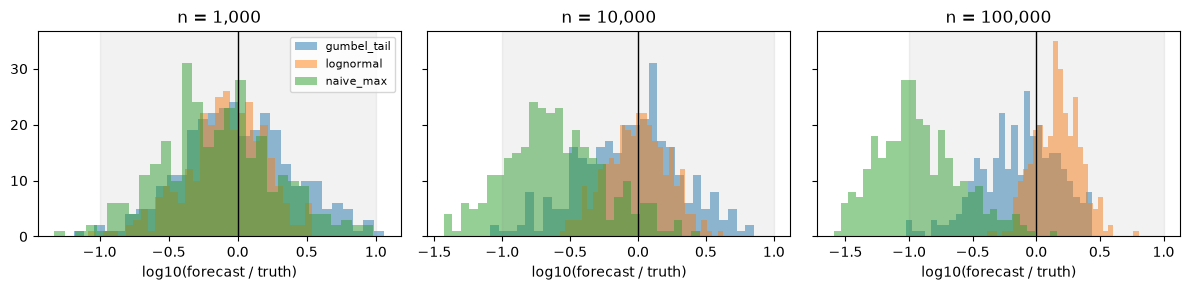

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, n in zip(axes, sorted(res_normal.n.unique())):
    sub = res_normal[res_normal.n == n]
    for name in METHODS:
        ax.hist(sub[sub.method == name].log10_err, bins=30, alpha=0.5, label=name)
    ax.axvline(0, color="k", lw=1); ax.axvspan(-1, 1, color="grey", alpha=0.1)
    ax.set_title(f"n = {n:,}"); ax.set_xlabel("log10(forecast / truth)")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## Step 11. Try to break it: a world with a fatter tail

A method that only works when the data is exactly the shape you assumed is not much use. In this second
world the rare queries are much worse than a normal tail predicts (a Student-t with 5 degrees of freedom: a narrower body but a fatter tail).
The log-normal baseline assumes the wrong shape; the tail method only looks at the top 10 points, so it
should adapt better.

In [5]:
res_fat = experiment(world_fat_tail, seed=1)
both = pd.concat({"logit-normal world": summarise(res_normal), "fat-tail world": summarise(res_fat)}, names=["world"])
both.xs("within_10x", axis=1).unstack("method")

method                     gumbel_tail  lognormal  naive_max
world              n                                        
logit-normal world 1000           0.99       1.00       0.99
                   10000          0.99       1.00       0.86
                   100000         1.00       1.00       0.56
fat-tail world     1000           0.70       0.41       0.66
                   10000          0.59       0.04       0.26
                   100000         0.66       0.00       0.12

In [6]:
summarise(res_fat)

within_10x  within_3x  under_forecast  median_log10_err
n      method                                                              
1000   gumbel_tail        0.70       0.41            0.63             -0.32
       lognormal          0.41       0.11            0.99             -1.14
       naive_max          0.66       0.38            0.73             -0.47
10000  gumbel_tail        0.59       0.34            0.82             -0.73
       lognormal          0.04       0.00            1.00             -1.95
       naive_max          0.26       0.11            0.94             -1.56
100000 gumbel_tail        0.66       0.33            0.98             -0.77
       lognormal          0.00       0.00            1.00             -1.97
       naive_max          0.12       0.05            1.00             -2.02

## Step 12. Write-up, and how this connects to your own project

**What the saved run found (300 repetitions per cell):**

- **When the shape is right, a simple parametric fit wins.** In the logit-normal world the log-normal
  baseline (which assumes exactly that shape) is within 10x every time and within 3x 96% of the time at
  n = 100,000. The tail method is also within 10x every time. The naive "worst seen in testing" falls to 56%
  within 10x at n = 100,000 and under-forecasts every time: testing alone badly understates deployment risk.
- **When the tail is fatter than assumed, the parametric fit collapses.** In the fat-tail world the
  log-normal is within 10x 0% of the time at n = 100,000 and under-forecasts in 100% of repetitions, by about
  two orders of magnitude. The tail method stays best (66% within 10x) **but still under-forecasts 98% of the
  time**. Ten points cannot see how fat the tail really is.
- **The lesson is the actuarial one:** the model of the tail, not the model of the body, decides the risk
  estimate, and every method here errs towards too low. Report the under-forecast share alongside accuracy,
  and add a margin or a fatter-tailed fit (for example a generalised Pareto) when the cost of being low is high.

How often each method lands within 10x, and whether it under-forecasts (the dangerous direction for risk),
are the two numbers to report. Compare against the paper: it reports 86% of
misuse forecasts within one order of magnitude from about 900 to about 90,000 queries, with the Gumbel-tail
method under-forecasting only 34% of the time (biased towards over-forecasting).

**Limitations:** the probabilities are simulated, so we know the truth exactly, which real work never does;
only one extrapolation shape; no distribution shift between testing and deployment (also a stated limitation
of the paper).

**Connection to your project:** replace "probability the model produces a bad output" with **"probability the
monitor misses an attack"**, estimated per attack from repeated trials as in notebook 01. The same tail fit
then forecasts the worst-case miss rate at deployment volume. That is the "estimate failure rates for rare
catastrophes" direction in Anthropic's list, and the actuarial risk modelling Brenton suggested.

**Next experiments:** vary m and k; add bootstrap intervals on each forecast; forecast the aggregate risk
(probability of at least one failure in n queries) rather than the single worst query.